# Clasificación de tumores cerebrales


In [1]:
!pip install ImageHash

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras import layers, models
from tensorflow.keras.utils import load_img, img_to_array
from sklearn.metrics import confusion_matrix, classification_report
from tensorflow.keras.callbacks import ReduceLROnPlateau, ModelCheckpoint

import os
import shutil
import random
from PIL import Image
import imagehash
from google.colab import drive
import zipfile

In [2]:
IMG_SIZE = (180, 180)
BATCH_SIZE = 32

TRAIN_DIR = "../dataset/Training"
TEST_DIR = "../dataset/Testing"

CLEAN_DIR = "../dataset_limpio"

CLEAN_TRAIN_DIR = os.path.join(CLEAN_DIR, "Training")
CLEAN_VAL_DIR = os.path.join(CLEAN_DIR, "Validation")

CLASSES = ["glioma", "meningioma", "notumor", "pituitary"]

In [3]:
# 1. Montar Google Drive
drive.mount('/content/drive')

zip_path = '/content/drive/MyDrive/Proyecto.zip'
extract_path = '/content/dataset'

# 2. Verificar existencia del archivo zip y descomprimir
if os.path.exists(zip_path):
    print(f"Archivo encontrado en: {zip_path}")

    os.makedirs(extract_path, exist_ok=True)
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)

    print("Contenido extraído:")
    print(os.listdir(extract_path))
else:
    print(f"El archivo no existe en la ruta: {zip_path}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Archivo encontrado en: /content/drive/MyDrive/Proyecto.zip
Contenido extraído:
['web', 'Proyecto', 'dataset_limpio_', 'dataset', 'notebooks', 'dataset_limpio']


In [4]:
# Rutas de origen y destino
base_path = '/content/dataset'
proyecto_path = os.path.join(base_path, 'Proyecto')

print("Contenido dentro de '/content/dataset/Proyecto':", os.listdir(proyecto_path))

# Mover carpetas de 'Proyecto' a '/content/dataset' si es necesario para cumplir con TRAIN_DIR y TEST_DIR
for folder in os.listdir(proyecto_path):
    src = os.path.join(proyecto_path, folder)
    dst = os.path.join(base_path, folder)
    if os.path.isdir(src) and not os.path.exists(dst):
        shutil.move(src, dst)
        print(f"Movido: {folder} -> {dst}")

print("\nEstructura final de '/content/dataset':", os.listdir(base_path))

Contenido dentro de '/content/dataset/Proyecto': ['web', 'dataset_limpio_', 'dataset', 'notebooks', 'dataset_limpio']

Estructura final de '/content/dataset': ['web', 'Proyecto', 'dataset_limpio_', 'dataset', 'notebooks', 'dataset_limpio']


In [5]:
# Corregir las rutas para apuntar a las carpetas reales extraídas
REAL_TRAIN_DIR = "/content/dataset/dataset_limpio_/Training"
REAL_VAL_DIR = "/content/dataset/dataset_limpio_/Validation"
REAL_TEST_DIR = "/content/dataset/dataset/Testing"

# Verificar y cargar los datasets desde las rutas reales corregidas
train_dataset = tf.keras.utils.image_dataset_from_directory(
    REAL_TRAIN_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=123
)

val_dataset = tf.keras.utils.image_dataset_from_directory(
    REAL_VAL_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_dataset = tf.keras.utils.image_dataset_from_directory(
    REAL_TEST_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)
TRAIN_DIR = REAL_TRAIN_DIR
TEST_DIR = REAL_TEST_DIR
CLEAN_TRAIN_DIR = REAL_TRAIN_DIR
CLEAN_VAL_DIR = REAL_VAL_DIR

Found 5208 files belonging to 4 classes.
Found 392 files belonging to 4 classes.
Found 1596 files belonging to 4 classes.


In [6]:
class_names = train_dataset.class_names

print("Clases:", class_names)

Clases: ['glioma', 'meningioma', 'notumor', 'pituitary']


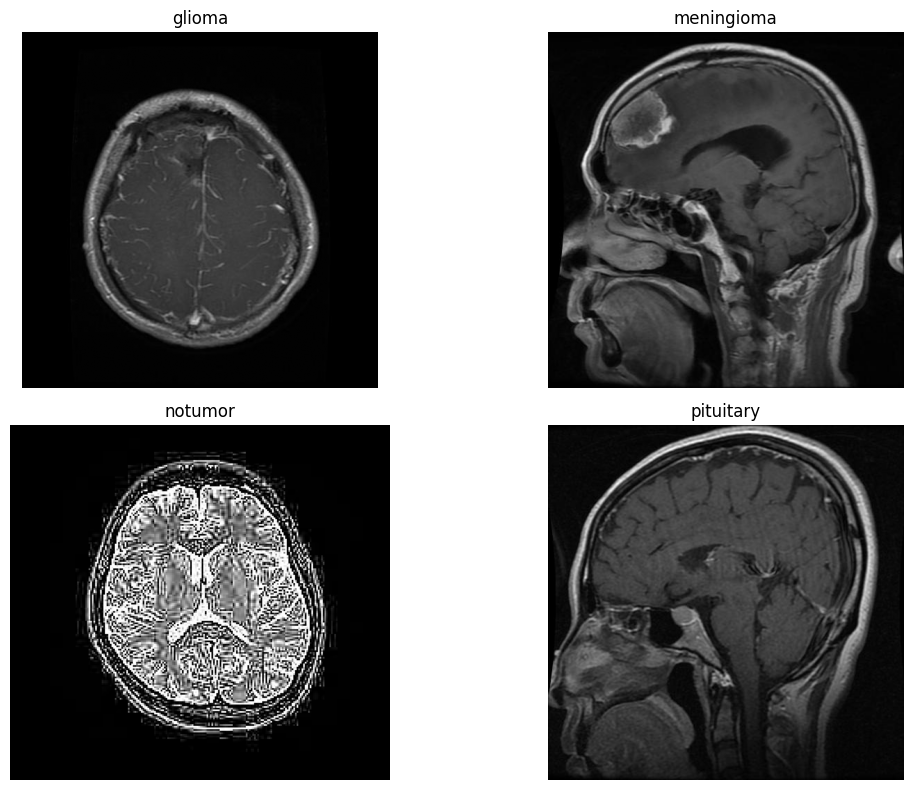

In [7]:
plt.figure(figsize=(12, 8))

for i, class_name in enumerate(class_names):
    class_path = os.path.join(TRAIN_DIR, class_name)

    image_name = os.listdir(class_path)[0]
    image_path = os.path.join(class_path, image_name)

    image = Image.open(image_path)

    plt.subplot(2, 2, i + 1)
    plt.imshow(image, cmap="gray")
    plt.title(class_name)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [8]:
def normalizar(imagenes, etiquetas):
    imagenes = tf.cast(imagenes, tf.float32) / 255.0
    return imagenes, etiquetas

train_dataset = train_dataset.map(normalizar)
val_dataset = val_dataset.map(normalizar)
test_dataset = test_dataset.map(normalizar)

In [ ]:
model = models.Sequential([

    layers.Input(shape=(180, 180, 3)),

    # BLOQUE 1
    layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),
    layers.Dropout(0.2),

    # BLOQUE 2
    layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),
    layers.Dropout(0.25),

    # BLOQUE 3
    layers.Conv2D(128, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.Conv2D(128, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),
    layers.Dropout(0.3),

    # BLOQUE 4
    layers.Conv2D(256, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.Conv2D(256, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),
    layers.Dropout(0.3),

    layers.Flatten(),

    layers.Dense(512, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.3),

    layers.Dense(256, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.3),

    layers.Dense(4, activation="softmax")
])

In [10]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 180, 180, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 180, 180, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 180, 180, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 180, 180, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 90, 90, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 90, 90, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 90, 90, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 90, 90, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 90, 90, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 90, 90, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 45, 45, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 45, 45, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 45, 45, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 45, 45, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 45, 45, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 45, 45, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 22, 22, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 22, 22, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 22, 22, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 22, 22, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 22, 22, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 17,223,848 (65.70 MB)

 Trainable params: 17,220,192 (65.69 MB)

 Non-trainable params: 3,656 (14.28 KB)

In [11]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [12]:
reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6
)

checkpoint = ModelCheckpoint(
    "mejor_modelo.keras",
    monitor="val_loss",
    save_best_only=True,
    mode="min"
)

In [13]:
history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=30,
    callbacks=[reduce_lr, checkpoint]
)

Epoch 1/30
163/163 ━━━━━━━━━━━━━━━━━━━━ 94s 338ms/step - accuracy: 0.7500 - loss: 0.7187 - val_accuracy: 0.2500 - val_loss: 8.5585 - learning_rate: 0.0010
Epoch 2/30
163/163 ━━━━━━━━━━━━━━━━━━━━ 25s 152ms/step - accuracy: 0.8316 - loss: 0.4666 - val_accuracy: 0.4133 - val_loss: 2.1832 - learning_rate: 0.0010
Epoch 3/30
163/163 ━━━━━━━━━━━━━━━━━━━━ 26s 158ms/step - accuracy: 0.8767 - loss: 0.3440 - val_accuracy: 0.5816 - val_loss: 1.6322 - learning_rate: 0.0010
Epoch 4/30
163/163 ━━━━━━━━━━━━━━━━━━━━ 24s 146ms/step - accuracy: 0.9109 - loss: 0.2652 - val_accuracy: 0.7883 - val_loss: 0.7246 - learning_rate: 0.0010
Epoch 5/30
163/163 ━━━━━━━━━━━━━━━━━━━━ 24s 147ms/step - accuracy: 0.9270 - loss: 0.2032 - val_accuracy: 0.8724 - val_loss: 0.3302 - learning_rate: 0.0010
Epoch 6/30
163/163 ━━━━━━━━━━━━━━━━━━━━ 24s 146ms/step - accuracy: 0.9386 - loss: 0.1633 - val_accuracy: 0.7551 - val_loss: 1.3272 - learning_rate: 0.0010
Epoch 7/30
163/163 ━━━━━━━━━━━━━━━━━━━━ 41s 143ms/step - accuracy: 0.9

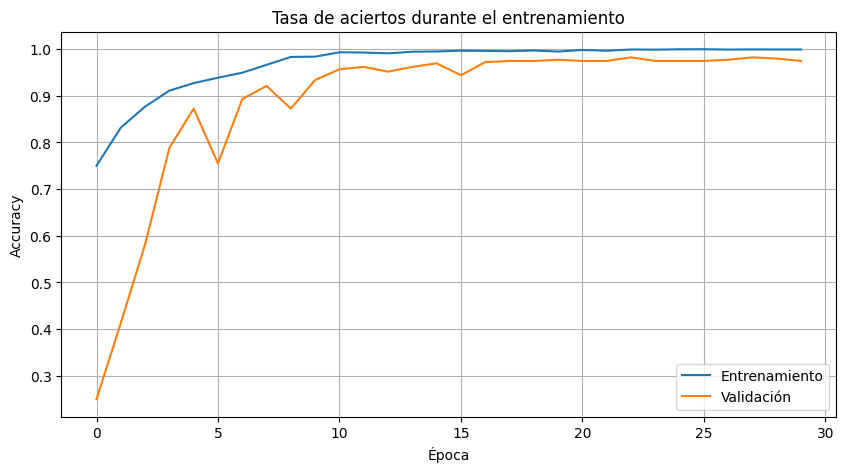

In [14]:
plt.figure(figsize=(10, 5))

plt.plot(history.history["accuracy"], label="Entrenamiento")
plt.plot(history.history["val_accuracy"], label="Validación")

plt.xlabel("Época")
plt.ylabel("Accuracy")
plt.title("Tasa de aciertos durante el entrenamiento")
plt.legend()
plt.grid()

plt.show()

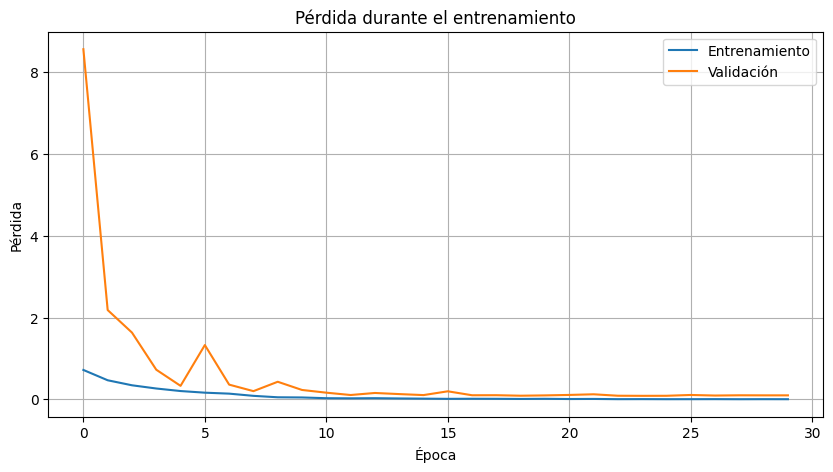

In [15]:
plt.figure(figsize=(10, 5))

plt.plot(history.history["loss"], label="Entrenamiento")
plt.plot(history.history["val_loss"], label="Validación")

plt.xlabel("Época")
plt.ylabel("Pérdida")
plt.title("Pérdida durante el entrenamiento")
plt.legend()
plt.grid()

plt.show()

In [16]:
mejor_modelo = models.load_model("mejor_modelo.keras")
test_loss, test_accuracy = mejor_modelo.evaluate(test_dataset)
print("Test Accuracy:", test_accuracy)
print("Test Loss:", test_loss)
model = mejor_modelo

50/50 ━━━━━━━━━━━━━━━━━━━━ 6s 84ms/step - accuracy: 0.9355 - loss: 0.4781
Test Accuracy: 0.9354636669158936
Test Loss: 0.47806429862976074


In [17]:
# Obtener las predicciones del conjunto de Testing
y_true = []
y_pred = []

for imagenes, etiquetas in test_dataset:

    predicciones = model.predict(imagenes, verbose=0)

    predicciones_clase = np.argmax(predicciones, axis=1)

    y_true.extend(etiquetas.numpy())
    y_pred.extend(predicciones_clase)

# Convertir a arrays
y_true = np.array(y_true)
y_pred = np.array(y_pred)

# Crear matriz de confusión
cm = confusion_matrix(y_true, y_pred)

print("Matriz de confusión:")
print(cm)

Matriz de confusión:
[[319  35  37   5]
 [  5 381   8   6]
 [  0   2 398   0]
 [  3   2   0 395]]


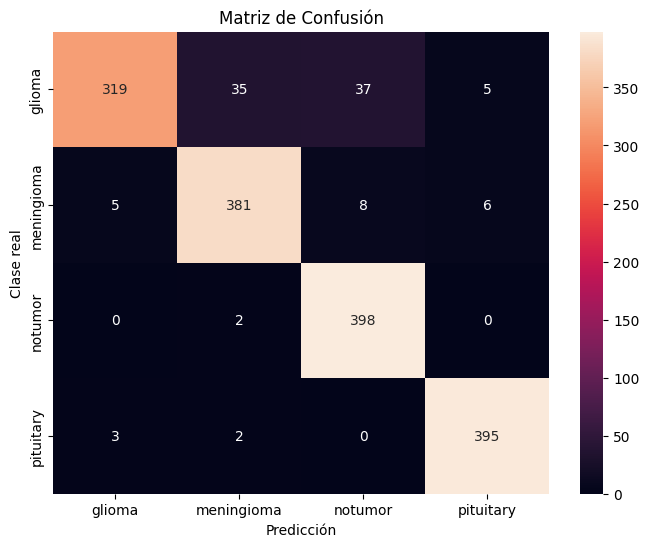

In [18]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicción")
plt.ylabel("Clase real")
plt.title("Matriz de Confusión")
plt.show()

In [19]:
print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names
    )
)

              precision    recall  f1-score   support

      glioma       0.98      0.81      0.88       396
  meningioma       0.91      0.95      0.93       400
     notumor       0.90      0.99      0.94       400
   pituitary       0.97      0.99      0.98       400

    accuracy                           0.94      1596
   macro avg       0.94      0.94      0.93      1596
weighted avg       0.94      0.94      0.93      1596



In [20]:
ruta_imagen = os.path.join(TEST_DIR, "glioma", "Te-gl_7.jpg")

imagen = Image.open(ruta_imagen).convert("RGB")

imagen = imagen.resize((180, 180))

imagen_array = np.array(imagen)

imagen_array = imagen_array.astype("float32") / 255.0

imagen_array = np.expand_dims(imagen_array, axis=0)

predicciones = model.predict(imagen_array, verbose=0)

print("\nPredicciones:")
for clase, probabilidad in zip(CLASSES, predicciones[0]):
    print(f"{clase}: {probabilidad * 100:.2f}%")


Predicciones:
glioma: 100.00%
meningioma: 0.00%
notumor: 0.00%
pituitary: 0.00%
